# **01_02 ChromaDB로 만드는 기본 RAG**



# 1. 환경 변수 설정

- OpenAI API Key 발급: https://platform.openai.com/api-keys

In [25]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("API Key가 설정되었습니다.")

API Key가 설정되었습니다.


# 2. PyMuPDF 문서 로딩 
PDF 문서 출처: https://spri.kr/posts/view/23992?code=AI-Brief&s_year=&data_page=1

https://wikidocs.net/239162

https://pypi.org/project/PyMuPDF/

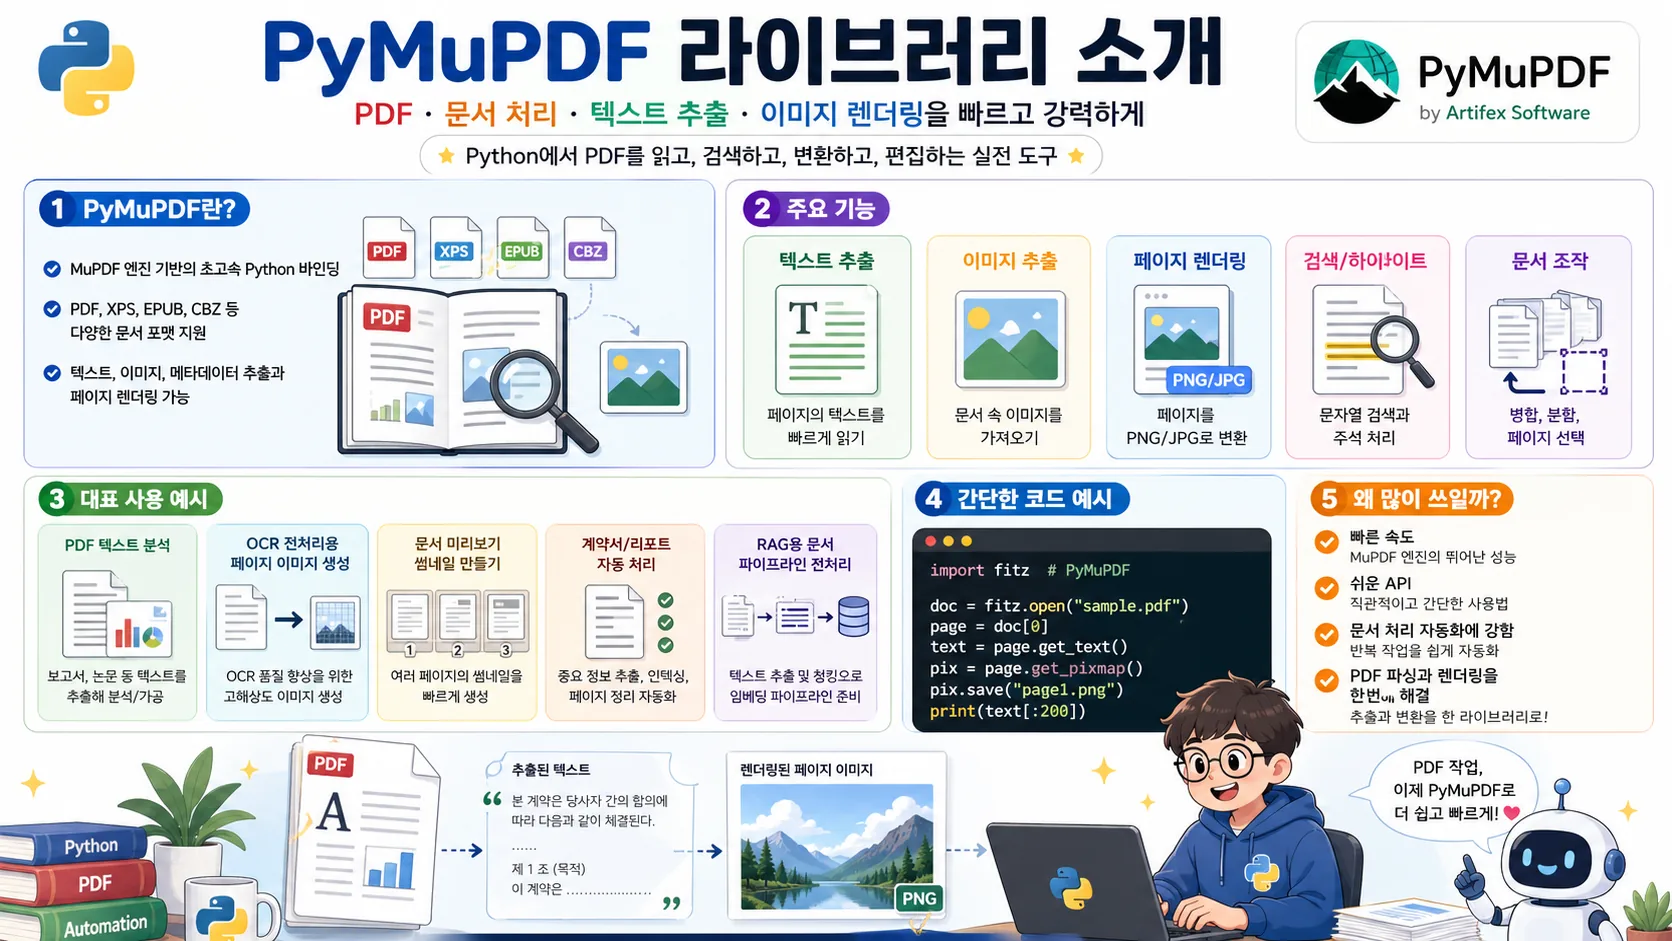

> **💡 Langchain Document 형식 확인하기**

```python
from langchain_core.documents import Document

document = Document(
    page_content="Hello, world!", metadata={"source": "https://example.com"}
)
```

In [26]:
from langchain_core.documents import Document  # LangChain의 표준 문서 객체
import fitz  # PyMuPDF 라이브러리 (PDF 처리용)

file_path = "dataset/SPRi AI Brief 6월호.pdf"

doc = fitz.open(file_path)  # PDF 파일 열기
docs = []  # LangChain Document 객체들을 담을 리스트

for page_num in range(len(doc)):  # 전체 페이지 수만큼 반복 (0부터 시작)
    page = doc[page_num]  # 현재 페이지 가져오기
    text = page.get_text("text", sort=True)  # 텍스트 추출 (읽기 순서대로 정렬)

    # Langchain Document 형식으로 변환
    docs.append(
        Document(
            page_content=text,  # 실제 텍스트 내용
            metadata={
                "source": file_path,   # 원본 파일 경로
                "page": page_num + 1   # 페이지 번호 (사람이 보기 편하게 1부터 시작)
            }
        )
    )

doc.close()  # PDF 문서 닫기 (리소스 해제)

## Chunking


In [27]:
from langchain_text_splitters import RecursiveCharacterTextSplitter  # 재귀적 텍스트 분할기

# child_splitter만 정의
# parent(페이지 단위)는 이미 docs로 존재하므로, 그걸 더 작은 child 청크로 쪼개는 splitter
child_splitter = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=50)  # 청크 크기 400자, 50자씩 겹치게 분할

print(f"페이지(parent) 문서 수: {len(docs)}")  # parent 문서(페이지) 개수 출력
print(f"child_splitter chunk_size: {child_splitter._chunk_size}")  # child_splitter에 설정된 청크 크기 확인

페이지(parent) 문서 수: 28
child_splitter chunk_size: 400


# 3. ChromaDB 벡터스토어 구축

ChromaDB는 오픈소스 벡터 데이터베이스로, 문서를 벡터로 변환하여 저장하고 유사도 검색을 수행합니다.

In [28]:
from langchain_chroma import Chroma  # Chroma 벡터스토어
from langchain_openai import OpenAIEmbeddings  # OpenAI 임베딩 모델


# 벡터스토어 (child chunk 임베딩 저장)
vectorstore = Chroma(
    collection_name="june_doc",            # 컬렉션(테이블) 이름
    embedding_function=OpenAIEmbeddings(),  # 텍스트를 벡터로 변환할 임베딩 모델 (OpenAI)
    persist_directory="./chroma_db"         # 벡터 데이터를 디스크에 저장할 경로 (재시작해도 유지됨)
)

In [29]:
print(vectorstore)

## Retriever 생성

Retriever는 벡터스토어를 래핑하여 검색 기능을 제공하는 인터페이스입니다.

In [30]:
from langchain_classic.retrievers import ParentDocumentRetriever  # parent-child 구조의 검색기
from langchain_core.stores import InMemoryByteStore  # 메모리에 데이터를 저장하는 바이트 스토어

# docstore (parent 페이지 원본 저장)
docstore = InMemoryByteStore()  # parent 문서(페이지 원본)를 메모리에 저장하는 저장소 (재시작하면 사라짐)

In [31]:
# ParentDocumentRetriever 생성
parent_retriever = ParentDocumentRetriever(
    vectorstore=vectorstore,        # child 청크 임베딩이 저장되는 벡터스토어 (실제 검색은 여기서 수행)
    docstore=docstore,              # parent 원본 문서가 저장되는 저장소
    child_splitter=child_splitter,  # parent를 child로 쪼개는 분할기
    parent_splitter=None,           # parent_splitter가 None이면 추가로 안 쪼개고, 페이지 자체를 parent로 사용
    search_kwargs={"k": 1}          # 검색 시 가장 유사한 child 1개만 반환 (-> 해당 child의 parent가 최종 결과)
)

In [32]:
# 문서 추가 (내부에서 자동으로 child chunk 생성 → vectorstore, parent page → docstore)
parent_retriever.add_documents(docs)  # docs(parent=페이지 단위)를 넣으면, 내부적으로 child_splitter로 쪼개서 vectorstore에 임베딩 저장하고, 원본 페이지는 docstore에 저장함

In [33]:
child_count = vectorstore._collection.count()  # vectorstore에 저장된 child 청크 개수 조회
parent_count = len(list(docstore.yield_keys()))  # docstore에 저장된 parent(페이지) 개수 조회 (key들을 모두 가져와서 개수 계산)

print(f"child chunk 수 (vectorstore): {child_count}")  # child 청크 개수 출력
print(f"parent page 수 (docstore): {parent_count}")    # parent 페이지 개수 출력
print(f"\n구조: page(parent) → chunk(child)")           # 구조 설명 출력
print(f"평균 chunk/page: {child_count / parent_count:.1f}")  # 페이지당 평균 청크 수 계산 및 출력

child chunk 수 (vectorstore): 573
parent page 수 (docstore): 28

구조: page(parent) → chunk(child)
평균 chunk/page: 20.5


#  Retriever Tool 기반 에이전트 구현

Retriever를 Tool로 정의하여 에이전트가 필요할 때만 문서를 검색하도록 합니다.

# Step 1: Retriever Tool 생성

In [34]:
from langchain_core.tools import create_retriever_tool  # retriever를 LLM이 호출할 수 있는 tool로 감싸주는 함수

retriever_tool = create_retriever_tool(
    parent_retriever,            # 내부적으로 호출될 retriever (ParentDocumentRetriever)
    "retrieve_AI_brief",         # tool 이름 (LLM이 tool을 선택할 때 사용)
    "Search and return information about AI Technology and Industry from SPRi AI Brief.",  # tool 설명 (LLM이 언제 이 tool을 써야 하는지 판단하는 기준)
)

tools = [retriever_tool]  # LLM에 바인딩할 tool 목록
print("Retriever Tool이 생성되었습니다.")

Retriever Tool이 생성되었습니다.


# Step 2: Graph 구성

In [35]:
from langgraph.graph import StateGraph, MessagesState  # 그래프 빌더, 기본 메시지 상태 스키마
from langgraph.prebuilt import ToolNode, tools_condition  # tool 실행 노드, tool 호출 여부를 판단하는 조건 함수

# 새로운 Graph Builder 생성
graph_builder = StateGraph(MessagesState)  # MessagesState 기반 그래프 빌더 새로 생성

# Tool Node 추가
tool_node = ToolNode(tools=tools)  # LLM이 호출한 tool(여기선 retriever_tool)을 실제로 실행해주는 노드
graph_builder.add_node("retriever", tool_node)  # "retriever"라는 이름으로 tool_node를 그래프에 등록

In [36]:
# LLM에 도구 바인딩
from langchain.chat_models import init_chat_model  # 모델 이름으로 chat model 객체를 생성하는 헬퍼
from langchain.messages import HumanMessage, SystemMessage  # 사용자/시스템 메시지 객체
from langgraph.graph import StateGraph, MessagesState  # 그래프 빌더와 기본 메시지 상태 스키마

llm = init_chat_model("gpt-5-mini")  # gpt-5-mini 모델로 LLM 객체 초기화
llm_with_tools = llm.bind_tools(tools)  # LLM에 tools(retriever_tool 등)를 바인딩 -> 필요시 LLM이 직접 tool 호출 결정 가능

def chatbot(state: MessagesState):
    """
    LLM이 사용자 질문을 분석하고 필요시 도구를 호출합니다.
    """
    return {"messages": [llm_with_tools.invoke(state["messages"])]} # tool_calls or AIMessage
    # state의 전체 메시지 기록을 LLM에 전달
    # LLM이 도구 호출이 필요하면 tool_calls가 담긴 AIMessage 반환, 아니면 일반 답변 AIMessage 반환

graph_builder.add_node("chatbot", chatbot)  # "chatbot"이라는 이름으로 chatbot 함수를 그래프에 노드로 등록

def answer(

In [37]:
from langchain.chat_models import init_chat_model  # 모델 이름으로 chat model 객체를 생성하는 헬퍼
from langchain.messages import HumanMessage, SystemMessage  # 사용자/시스템 메시지 객체

llm = init_chat_model("gpt-5-mini")  # gpt-5-mini 모델로 LLM 객체 초기화

def answer(state: MessagesState):
    """
    검색된 문서를 기반으로 사용자 질문에 답변합니다.
    """
    print("##### ANSWER #####")
    query = state["messages"][0].content   # 첫 번째 메시지 = 원래 사용자 질문
    context = state["messages"][-1].content  # 마지막 메시지 = retriever 노드가 만든 검색 결과(context)

    SYSTEM_PROMPT = f"""
    당신은 관련 문서를 기반으로 답변하는 어시스턴트입니다.
    주어진 문서 텍스트를 기반으로 사용자의 질문에 대해 충실히 답변하세요.
    답변은 마크다운 문법 형식으로 적절한 볼드체, 제목, 불렛 등을 사용하여 가독성 좋게 작성하세요.
    """
    system_msg = SystemMessage(SYSTEM_PROMPT)  # 위 지침을 시스템 메시지로 생성
    human_msg = HumanMessage(f"""
    다음은 주어진 문서 텍스트입니다.
    <context>
    {context}
    </context>

    <question>
    {query}
    </question>
    """)  # context와 question을 함께 담은 사용자 메시지 생성 (RAG 프롬프트)

    response = llm.invoke(
        [system_msg, human_msg]  # 시스템 메시지 + 사용자 메시지를 LLM에 전달하여 답변 생성
    )

    print(f"[생성된 답변]\n{response.content}\n")  # 생성된 답변 내용 출력

    return {"messages": [response]} # AIMessage  # 생성된 AIMessage를 state에 추가하여 반환 (다음 노드/최종 결과로 전달됨)

**tools_condition**: 마지막 메시지에 tool_calls가 있으면 ToolNode로 라우팅, 없으면 END로 이동

In [38]:
# 조건부 엣지 추가
from langgraph.graph import END, START  # 그래프 시작/종료 노드


graph_builder.add_conditional_edges(
    "chatbot",          # chatbot 노드 실행 후 분기
    tools_condition,    # chatbot의 응답에 tool_calls가 있는지 확인하는 조건 함수
    {
        "tools": "retriever",  # tool_calls가 있으면 -> "retriever"(tool_node)로 이동
        END: END                # tool_calls가 없으면(일반 답변) -> 그래프 종료
    }
)

# Answer 노드 추가
graph_builder.add_node("answer", answer)  # 검색된 문서를 기반으로 최종 답변을 생성하는 노드 등록

# 엣지 연결
graph_builder.add_edge(START, "chatbot")      # 그래프 시작 -> chatbot 노드 (먼저 LLM이 질문 분석)
graph_builder.add_edge("retriever", "answer")  # retriever(tool 실행) 후 -> answer 노드로 이동해 최종 답변 생성
graph_builder.add_edge("answer", END)          # answer 노드 -> 그래프 종료

# 그래프 컴파일
graph = graph_builder.compile()
# 전체 흐름: START -> chatbot -> (tool 필요시 retriever -> answer -> END) / (필요없으면 바로 END)

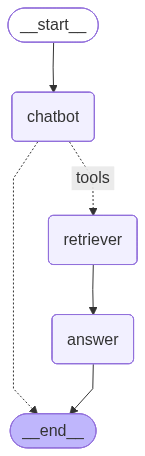

In [39]:
# 그래프 시각화
from IPython.display import Image, display
# 그래프 시각화
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(e)

# Step 3: 에이전트 실행 테스트

In [40]:
# 문서 검색이 필요한 질문
response = graph.invoke({
    "messages": "앤트로픽이 분석한 AI의 영향력"
})

print("\n" + "=" * 80)
print("[에이전트 실행 결과 - 문서 검색 필요]")
print("=" * 80)
for msg in response['messages']:
    msg.pretty_print()

##### ANSWER #####
[생성된 답변]
**요청하신 문서가 제공되지 않았습니다**

- 현재 주어진 문서 텍스트(<context>)가 비어 있어, “주어진 문서 텍스트를 기반으로” 답변할 수 없습니다.
- 문서에 기반한 정확한 요약·분석을 원하시면 관련 문서(또는 문서의 주요 내용)을 업로드하거나 붙여 넣어 주세요.

원하시면 두 가지 방식으로 도와드릴 수 있습니다. 선택해 주세요:

1. **문서 기반 요약 제공** — 사용자가 문서를 올려주시면 그 문서 내용을 바탕으로 요약·분석해 드립니다.  
2. **공개된 자료에 기반한 일반적 요약 제공** — 제공된 문서가 없어도, Anthropic(앤트로픽)이 공개적으로 발표하거나 알려진 관점·분석을 바탕으로 AI의 영향력에 관한 요약을 지금 바로 제공해 드릴 수 있습니다. (주의: 이 경우 답변은 사용자가 제공한 문서가 아닌 공개 정보에 근거합니다.)

아래는 2번을 선택하실 경우에 제공할 수 있는 “간단한 일반 요약(공개 정보 기준)”의 예시입니다. 원하시면 더 자세히 확장해 드리겠습니다.

**Anthropic(앤트로픽)이 공개적으로 강조해온 주요 관점(요약, 공개 자료 기반)**

- 목적과 배경  
  - 앤트로픽은 AI 안전과 정렬(alignment)에 중점을 둔 연구 중심 기업으로, 고성능 대형 언어모델(LLM)이 초래할 수 있는 위험을 줄이는 기술과 정책을 개발하는 데 집중합니다.

- 주요 우려와 분석 포인트  
  - 변혁적 영향(transformative impact): 고급 AI가 경제·정치·안보·사회구조에 큰 변화를 초래할 가능성을 인정합니다.  
  - 정렬 문제(alignment): 모델 목표와 인간 가치가 일치하지 않을 때 발생하는 오작동·악용 위험을 중요하게 봅니다.  
  - 악용·오남용(dual-use): 강력한 모델의 악용 가능성(허위정보, 자동화된 공격, 사기 등)을 경고합니다.  
  - 확장성의 위험(scale-related risks): 모델 규모와 성능이 증가

In [42]:
# 문서 검색이 불필요한 일반 대화
for chunk in graph.stream({"messages": "안녕하세요, 반갑습니다!"}):
    for node, value in chunk.items():
        if node:
            print(f"===== {node} =====")
        if "messages" in value:
            print(value['messages'][0].content)
            print()

===== chatbot =====
안녕하세요! 반갑습니다 😊  
무엇을 도와드릴까요? 궁금한 점이나 요청하실 일이 있으면 편하게 말씀해 주세요.



# Gradio 추가

In [ ]:
import gradio as gr
from langchain_core.messages import AIMessageChunk

def chat_fn(message, history):
    final_answer = ""
    yielded = False  # 최소 한 번이라도 yield 했는지 체크

    for chunk_msg, metadata in graph.stream({"messages": message}, stream_mode="messages"):
        if isinstance(chunk_msg, AIMessageChunk) and chunk_msg.content:
            # answer 노드 조건을 빼거나, 디버깅 후 정확한 노드명으로 맞추세요
            final_answer += chunk_msg.content
            yielded = True
            yield final_answer

    if not yielded:
        # 스트리밍 조각이 하나도 없었다면, 전체 invoke 결과로 한 번 더 시도 (fallback)
        response = graph.invoke({"messages": message})
        yield response["messages"][-1].content


demo = gr.ChatInterface(
    fn=chat_fn,
    title="AI Brief 문서 기반 RAG 에이전트",
    description="필요한 경우 문서를 검색해서 답변하는 에이전트입니다.",
)

demo.launch()

c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\gradio\chat_interface.py:347: UserWarning: The 'tuples' format for chatbot messages is deprecated and will be removed in a future version of Gradio. Please set type='messages' instead, which uses openai-style 'role' and 'content' keys.
  self.chatbot = Chatbot(


* Running on local URL:  http://127.0.0.1:7862
* To create a public link, set `share=True` in `launch()`.


##### ANSWER #####
[생성된 답변]
**요약 — 앤트로픽이 분석한 AI의 영향력**

1. **지정학·패권 변화**
   - AI는 2028년 글로벌 패권 향방을 결정하는 핵심 요인으로 작용. 미국·민주주의 진영이 AI 우위를 유지하면 글로벌 규범 주도와 강력한 억지력(대중국)을 확보할 수 있음.
   - 반대로 민주주의 진영이 우위를 잃거나 정책 실패 시, 중국은 단기간 내(수개월 차이) 빠르게 격차를 좁혀 영향력을 확대하고 권위주의 모델을 세계에 확산시킬 수 있음.

2. **안보·군사적 영향**
   - AI 기반 사이버 전력과 정보전 능력이 국가간 위협의 핵심 요소가 됨. 중국이 AI로 사이버 역량을 강화하면 심각한 안보 위협으로 부상.
   - 미국의 사이버보안 역량 강화 여부가 민주주의 진영의 억지력 유지에 직결됨.

3. **경제·산업 영향**
   - 첨단 반도체(특히 AI 칩)가 AI 경쟁의 핵심 입력요소로, 반도체 우위가 곧 AI 우위로 연결됨.
   - 중국 기업(화웨이·알리바바 등)이 개발도상국 시장에서 인프라 점유를 확대하면 중국 주도의 AI 생태계가 글로벌 인프라·시장에 뿌리내릴 가능성.

4. **기술 탈취 및 비공식 확산 위험**
   - 불법 수단(칩 밀수, ‘증류(distillation) 공격’)으로 프런티어 모델 역량을 불법 복제·축적할 수 있어 우위가 빠르게 잠식될 위험이 존재.
   - 현재 미국 모델이 성능·지능 면에서 몇 달 이상 앞서 있지만, 위 불법 경로로 격차가 감소할 수 있음.

5. **규범·거버넌스 영향**
   - AI 주도권을 쥔 진영이 글로벌 규범·표준을 형성하게 되고, 이는 민주주의·권위주의 가치 확산에 직결됨.
   - 민주주의 진영의 정책 대응(수출통제, 수사·제재, 정보공유, AI 수출 촉진)에 따라 국제 질서가 달라짐.

6. **앤트로픽의 권고(민주주의 우위 확보를 위한 핵심 과제)**
   - 첨단 반도체·장비에 대한 수출통제·단속 강화로 중국의 우회적 컴퓨팅 접근 차단.
  